 בתור התחלה נקח את הטבלה מהאתר של קגל ונפתח אותה בפייתון בעזרת הספרייה פנדס. אני לוקח מהטבלה רק את העמודות שאני הולך להשתמש בהם בלמידת מכונה.

In [8]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "rush4ratio/video-game-sales-with-ratings",  # Dataset handle
    "Video_Games_Sales_as_at_22_Dec_2016.csv",  # Target filename
    pandas_kwargs={
        "usecols": ["Name", "Year_of_Release", "Critic_Score", "User_Score", "Publisher", "Critic_Count", "User_Count", "Rating"]
    }
)

Using Colab cache for faster access to the 'video-game-sales-with-ratings' dataset.


לאחר מכן אני אדפיס את השורות הראשונות של הטבלה שפתחתי בבלוק הקודם.

In [9]:
df.head()

,Name,Year_of_Release,Publisher,Critic_Score,Critic_Count,User_Score,User_Count,Rating
0,Wii Sports,2006.0,Nintendo,76.0,51.0,8,322.0,E
1,Super Mario Bros.,1985.0,Nintendo,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,2008.0,Nintendo,82.0,73.0,8.3,709.0,E
3,Wii Sports Resort,2009.0,Nintendo,80.0,73.0,8,192.0,E
4,Pokemon Red/Pokemon Blue,1996.0,Nintendo,NaN,NaN,NaN,NaN,NaN


בנוסף אני אדפיס את הכמות שורות ועמודות שיש בטבלה

In [10]:
print("Amount of rows : ",df.shape[0])
print("Amount of Colomns : ",df.shape[1])

Amount of rows :  16719
Amount of Colomns :  8


שם הוא קטגוריה, המייצג את שם משחק הווידאו. שנת יציאה היא מספר, המייצג את השנה שבה המשחק יצא לשוק. מפיצה היא קטגוריה, המייצגת את החברה שהפיצה והוציאה לאור את המשחק. ציון המבקרים הוא מספר, המייצג את הציון הממוצע שקיבל המשחק ממבקרי משחקים מקצועיים. מספר המבקרים הוא מספר, המייצג את כמות המבקרים המקצועיים שכתבו ביקורת ונתנו ציון למשחק. ציון המשתמשים הוא מספר, המייצג את הציון הממוצע שניתן למשחק על ידי שחקנים מהקהל הרחב. מספר המשתמשים הוא מספר, המייצג את כמות השחקנים מהקהל הרחב שדירגו את המשחק. סיווג גיל הוא קטגוריה, המייצג את דירוג ההתאמה לגילאים של המשחק לפי ארגוני הסמכה.

עכשיו אני אציג כמה ערכים חסרים יש בכל עמודה.

In [11]:
print("--- Missing values per column ---")
for column in df.columns:
    missing_count = df[column].isnull().sum()
    print(f"Column '{column}': {missing_count} missing values")

--- Missing values per column ---
Column 'Name': 2 missing values
Column 'Year_of_Release': 269 missing values
Column 'Publisher': 54 missing values
Column 'Critic_Score': 8582 missing values
Column 'Critic_Count': 8582 missing values
Column 'User_Score': 6704 missing values
Column 'User_Count': 9129 missing values
Column 'Rating': 6769 missing values


לפי דעתי, חסר הרבה דירוגים של משחקים מכיוון שמשחקים ישנים רבים יצאו לשוק לפני שהוקמו ארגוני הסמכה רשמיים בעולם. בנוסף, משחקים קטנים רבים, או משחקים שיצאו רק ביפן, לא עברו מעולם תהליך דירוג רשמי במערב, וגם לא זכו לביקורות של גולשים או מבקרים מקצועיים באינטרנט.

עכשיו אני אדפיס את הממוצע של כל עמודה מספרית,

In [12]:
import pandas as pd


df['User_Score'] = pd.to_numeric(df['User_Score'], errors='coerce')


numerical_columns = [
    'Year_of_Release',
    'Critic_Score',
    'Critic_Count',
    'User_Score',
    'User_Count'
]

print("--- Averages for specified numerical columns ---")
for col in numerical_columns:

    col_mean = df[col].mean()
    print(f"Column '{col}' mean: {col_mean:.2f}")

--- Averages for specified numerical columns ---
Column 'Year_of_Release' mean: 2006.49
Column 'Critic_Score' mean: 68.97
Column 'Critic_Count' mean: 26.36
Column 'User_Score' mean: 7.13
Column 'User_Count' mean: 162.23


אני חושב שזה הגיוני שהממוצע של העמודה שקובעת באיזה שנה משחק יצא הוא 2006 מכיוון שבתקופה זו משחקי מחשב הפכו למשהו הרבה יותר פופולרי בקרב אנשים רגילים ולכן חברות ניסו להוציא כמה שיותר משחקים בתקופה זאת, בנוסף אני חושב שזה הגיוני שהממוצע של כמות המבקרים המקצועיים הוא רק 26 מכיוון שלרוב רק למשחקים גדולים מאוד יש הרבה מאוד מבקרים וזאת נשמעת לי כמות רגילה .

שלושת העמודות שבחרתי הם : 1. השנה שבה יצא המחשק, בחרתי בזה בגלל שכמו שראינו מקודם השנה הממוצעת שבה יצאו המשחקים היא 2006 ולכן אני חושב שגם הרבה יותר יחידות יכלו להימכר לכל משחק בפני עצמו בשנה הזאת מכיוון שהיה כזה הרבה ביקוש למשחקי וידאו. 2. הדירוג שהמבקרים המקצועיים נתנו למשחק , אני חושב שזה חשוב בגלל שמבקרים מקצועיים מדרגים לפי דברים מאוד ספציפים ולרוב גם כאשר הדירוג שלהם גבוה יותר כך המשחק הזה ימכר. 3. אני בוחר בכמות הדירוגים על ידי המבקרים מכיוון שככל שיותר מבקרים מקצועיים השקיעו מזמנם בלבקר את המשחק , כנראה שהמשחק הזה מפורסם ומכר הרבה יחידות.

הגרף הראשון שאני מראה הוא הקשר בין כמות המבקרים המקצועיים לבין השנה שבה יצא המשחק

> Add blockquote



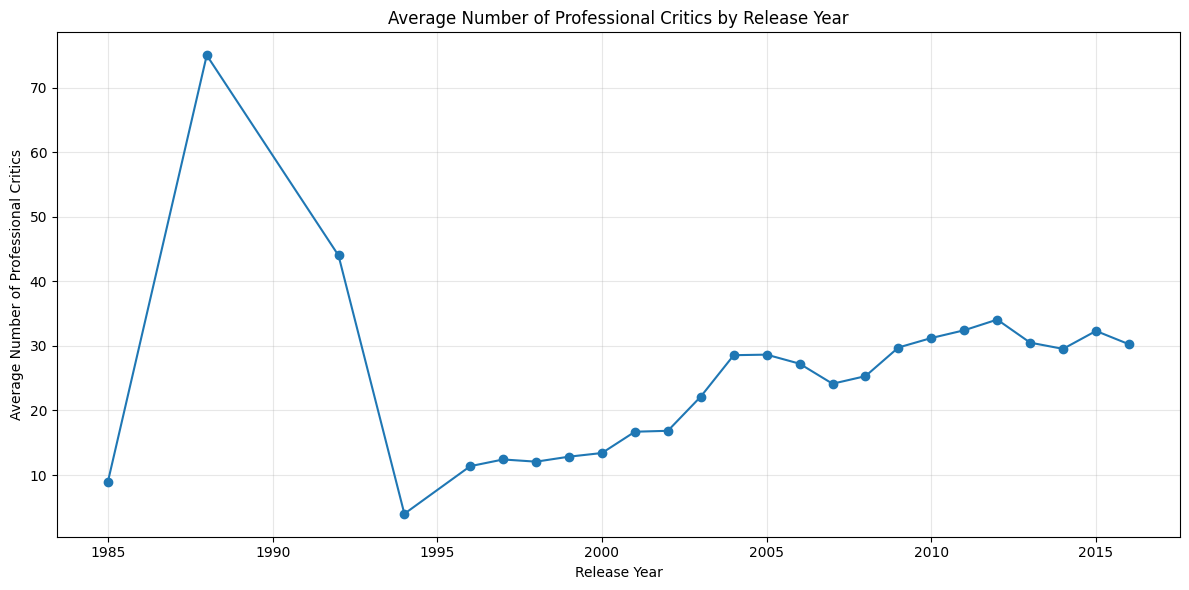

In [21]:

import matplotlib.pyplot as plt
import pandas as pd

# Remove rows with missing values
df_filtered = df.dropna(
    subset=['Year_of_Release', 'Critic_Count']
).copy()

# Convert columns to numeric values
df_filtered['Year_of_Release'] = pd.to_numeric(
    df_filtered['Year_of_Release'], errors='coerce'
)
df_filtered['Critic_Count'] = pd.to_numeric(
    df_filtered['Critic_Count'], errors='coerce'
)

df_filtered = df_filtered.dropna(
    subset=['Year_of_Release', 'Critic_Count']
)

# Calculate the average critic count for each year
average_critics = (
    df_filtered.groupby('Year_of_Release')['Critic_Count']
    .mean()
    .sort_index()
)

# Plot a linear-style graph
plt.figure(figsize=(12, 6))

plt.plot(
    average_critics.index,
    average_critics.values,
    marker='o',
    linestyle='-'
)

plt.title('Average Number of Professional Critics by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Number of Professional Critics')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


המסקנה היא שכאשר משחקי מחשב נהיו פופולרים היו הרבה מאוד מבקרים מקצועיים באזור ה70 ולאחר מכן הייתה ירידה חדה ועם השנים כמות המבקרים המקצועיים עולה

הגרף השני מראה את 15 המפרסמים שקיבלו בממוצע את הדירוגים הכי גבוהים על ידי מבקרים מקצועיים

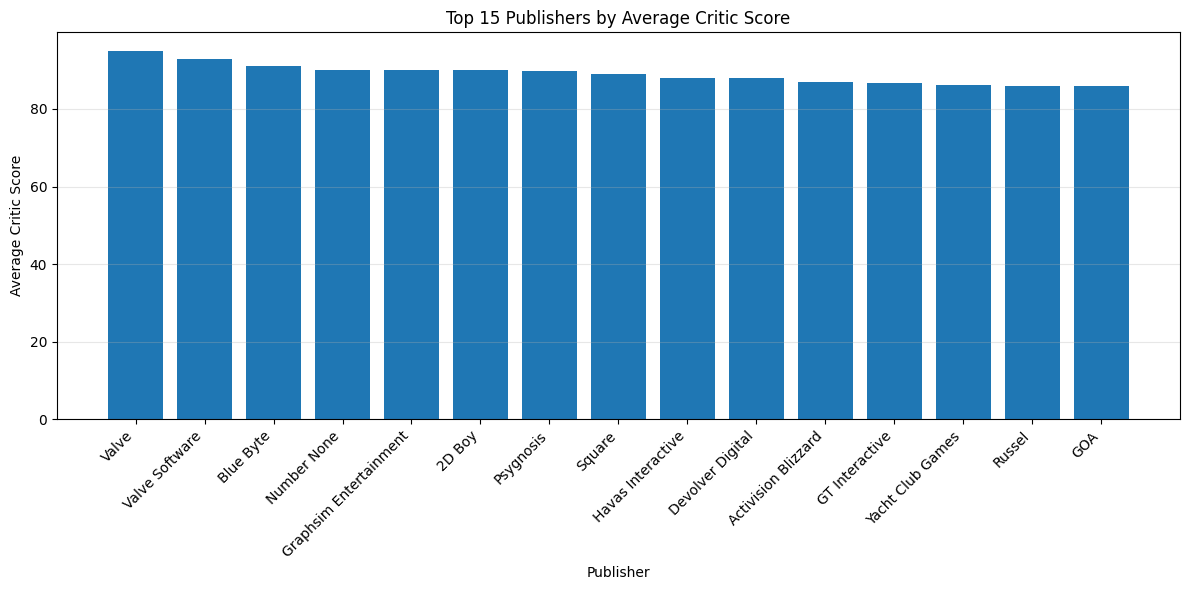

In [22]:

import matplotlib.pyplot as plt
import pandas as pd

# Remove rows with missing values
df_publisher = df.dropna(
    subset=['Publisher', 'Critic_Score']
).copy()

df_publisher['Critic_Score'] = pd.to_numeric(
    df_publisher['Critic_Score'], errors='coerce'
)

df_publisher = df_publisher.dropna(
    subset=['Critic_Score']
)

# Calculate average critic score for each publisher
publisher_ratings = (
    df_publisher.groupby('Publisher')['Critic_Score']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

# Plot the graph
plt.figure(figsize=(12, 6))
plt.bar(publisher_ratings.index, publisher_ratings.values)

plt.title('Top 15 Publishers by Average Critic Score')
plt.xlabel('Publisher')
plt.ylabel('Average Critic Score')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


המסקנה היא שבאמת החברה שמקבלת את הדירוגים הכי גבוהים בממוצע שהיא ולו באמת היום שולטת בשוק משחקי המחשב

הגרף השלישי מראה את הקשר שבין השנה לבין כמות המשחקים שפורסמו בה

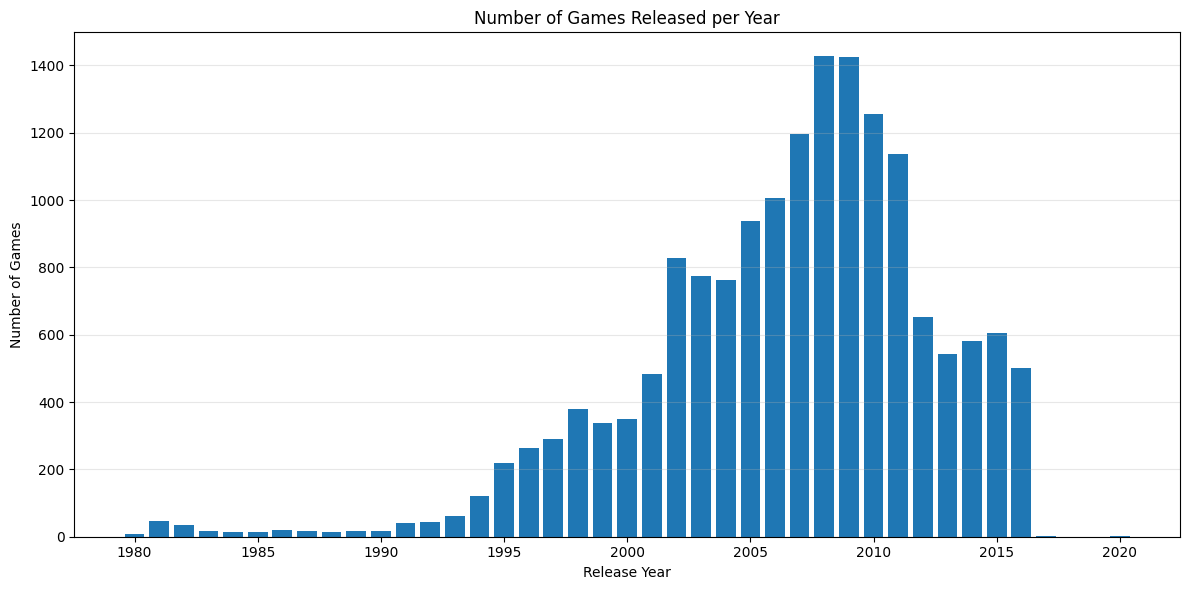

In [23]:

import matplotlib.pyplot as plt
import pandas as pd

# Remove rows with missing release years
df_years = df.dropna(
    subset=['Year_of_Release']
).copy()

df_years['Year_of_Release'] = pd.to_numeric(
    df_years['Year_of_Release'], errors='coerce'
)

df_years = df_years.dropna(
    subset=['Year_of_Release']
)

# Count games released each year
games_per_year = (
    df_years.groupby('Year_of_Release')
    .size()
    .sort_index()
)

# Plot the graph
plt.figure(figsize=(12, 6))
plt.bar(games_per_year.index, games_per_year.values)

plt.title('Number of Games Released per Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Games')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


המסקנה מהגרף היא שככל שאנחנו מתקדמים בשנים הגרף מתפרסמים יותר משחקים ושבאזור אלפיים ושבע נוצרו הרבה מאוד משחקים וזה הגיוני כי זאת הייתה תקופה בה משחקי וידאו היו מאוד פופולרים בשל העובדה שבערך בתקופה הזאת בערך הגיעו לשוק הפלייסטישן והאקסבוקס החדש